# Análisis de Centralidad de una Red Ciclista

**Objetivo:** A partir de una red ciclista en formato GeoPackage (líneas), construir un grafo topológico y calcular métricas de centralidad para **cada vértice** (intersecciones y extremos de ciclovía).

**Métricas sobre nodos:**
- **Degree:** número de segmentos ciclistas que confluyen en el vértice.
- **Betweenness:** fracción de caminos más cortos (en metros) que pasan por el vértice — identifica puntos de paso obligado.
- **Betweenness local:** igual que betweenness, pero solo cuenta pares de vértices a ≤ R metros por la red (viajes de rango ciclista).
- **Closeness:** inverso de la distancia media (en metros) al resto de los vértices alcanzables.
- **Harmonic closeness:** variante de closeness robusta a redes fragmentadas (frecuente en redes ciclistas).
- **Straightness:** qué tan "directas" son las rutas desde el vértice (distancia euclidiana / distancia por red).
- **PageRank:** importancia ponderada por la importancia de los vecinos.
- **Componente:** identificador y tamaño del componente conexo al que pertenece el vértice.

**Preprocesamiento de red:**
- Se reproyecta a un CRS métrico (EPSG:6372 por defecto).
- Se separan las multilíneas y, opcionalmente, se **nodifican** las líneas (se cortan en cada cruce).
- Se unen extremos cercanos con una tolerancia de *snap* (corrige pequeños errores de digitalización).
- Opcionalmente se eliminan los **nodos de grado 2** (pseudo-nodos que solo parten una línea continua).

## 1. Importaciones

In [67]:
import os
import warnings

import geopandas as gpd
import pandas as pd
import numpy as np
import networkx as nx
import shapely
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

warnings.filterwarnings('ignore')

print(f'GeoPandas: {gpd.__version__}')
print(f'Shapely  : {shapely.__version__}')
print(f'NetworkX : {nx.__version__}')

GeoPandas: 1.1.2
Shapely  : 2.1.2
NetworkX : 3.4.2


## 2. Parámetros del análisis

In [68]:
# ─── AJUSTA ESTOS VALORES ────────────────────────────────────────────────────

RUTA_GPKG = r'G:/Mi unidad/Trabajo/red_grafos_red_ciclistaOaxaca.gpkg'   # <-- PLACEHOLDER: ruta al GeoPackage
CAPA      = None                                    # nombre de la capa; None = primera capa

CRS_METRICO = 'EPSG:6372'      # CRS proyectado en metros (México LCC)

TOLERANCIA_SNAP = 1.0          # metros — extremos a menos de esta distancia se unen en un vértice

# True: corta las líneas en cada cruce (útil si la red no está topológicamente nodificada).
# False: solo conecta extremos de línea (respeta pasos a desnivel).
NODIFICAR_INTERSECCIONES = True

# True: fusiona segmentos unidos por vértices de grado 2 (pseudo-nodos).
SIMPLIFICAR_GRADO_2 = True

# True: calcula métricas solo en el componente conexo más grande.
# False: calcula en toda la red (closeness/straightness se evalúan dentro de cada componente).
SOLO_COMPONENTE_PRINCIPAL = False

# Betweenness: None = exacto (lento en redes grandes); ej. 500 = aproximado con k nodos muestra
K_BETWEENNESS = None

# Betweenness local: solo cuenta pares de vértices a <= R metros por la red.
# Lista de radios en metros (uno o varios); [] = no calcular.
RADIOS_LOCAL = [2000, 5000]

# Straightness requiere todas las distancias por red, O(n²) — desactivar en redes > ~5,000 nodos
CALCULAR_STRAIGHTNESS = True

# Carpeta y nombre de salida
OUTPUT_DIR    = 'datos/red_ciclista'
NOMBRE_SALIDA = 'red_ciclista_centralidad'

# ─────────────────────────────────────────────────────────────────────────────

print(f'Archivo        : {RUTA_GPKG}')
print(f'Capa           : {CAPA}')
print(f'CRS métrico    : {CRS_METRICO}')
print(f'Snap           : {TOLERANCIA_SNAP} m')
print(f'Nodificar      : {NODIFICAR_INTERSECCIONES}')
print(f'Simplificar g2 : {SIMPLIFICAR_GRADO_2}')

Archivo        : G:/Mi unidad/Trabajo/red_grafos_red_ciclistaOaxaca.gpkg
Capa           : None
CRS métrico    : EPSG:6372
Snap           : 1.0 m
Nodificar      : True
Simplificar g2 : True


## 3. Carga de la red ciclista

In [69]:
if CAPA is None and hasattr(gpd, 'list_layers'):
    print('Capas disponibles:')
    print(gpd.list_layers(RUTA_GPKG).to_string(index=False))

red = gpd.read_file(RUTA_GPKG, layer=CAPA)
print(f'\nRegistros       : {len(red):,}')
print(f'CRS original    : {red.crs}')
print(f'Tipos geometría : {red.geom_type.value_counts().to_dict()}')
red.head()

Capas disponibles:
                         name     geometry_type
red_grafos_red_ciclistaoaxaca MultiLineString Z

Registros       : 274
CRS original    : EPSG:32614
Tipos geometría : {'MultiLineString': 274}


,Vialidades,Tipo_Ciclo,Caract,Plazo,Situacion,Propuesto,Delimitado,Superficie,Calidad,Longitud,...,Ancho_Via,Est_Delim,Obstaculos,Ancho_Cicl,i,j,ij,long_m,networkGrp,geometry
0,Av. Riveras del Rio y Mariano Azuela,P,P,Corto,Vialidad amplia,Ciclovia unidireccional de ambos sentidos conf...,N/A,Asfalto,BUENO,2.281,...,,,,,0,1,0-1,172.302,0,"MULTILINESTRING Z ((741482.754 1886423.998 0, ..."
1,Av. Riveras del Rio y Mariano Azuela,P,P,Corto,Vialidad amplia,Ciclovia unidireccional de ambos sentidos conf...,N/A,Asfalto,BUENO,2.281,...,,,,,0,1,0-1,238.663,0,"MULTILINESTRING Z ((741648.843 1886468.304 0, ..."
2,Av. Riveras del Rio y Mariano Azuela,P,P,Corto,Vialidad amplia,Ciclovia unidireccional de ambos sentidos conf...,N/A,Asfalto,BUENO,2.281,...,,,,,0,1,0-1,146.175,0,"MULTILINESTRING Z ((741877.052 1886538.422 0, ..."
3,Av. Riveras del Rio y Mariano Azuela,P,P,Corto,Vialidad amplia,Ciclovia unidireccional de ambos sentidos conf...,N/A,Asfalto,BUENO,2.281,...,,,,,0,1,0-1,37.596,0,"MULTILINESTRING Z ((742017.14 1886580.331 0, 7..."
4,Av. Riveras del Rio y Mariano Azuela,P,P,Corto,Vialidad amplia,Ciclovia unidireccional de ambos sentidos conf...,N/A,Asfalto,BUENO,2.281,...,,,,,0,1,0-1,1406.391,0,"MULTILINESTRING Z ((742053.171 1886591.109 0, ..."


Segmentos tras limpieza : 274
Longitud total          : 253.32 km


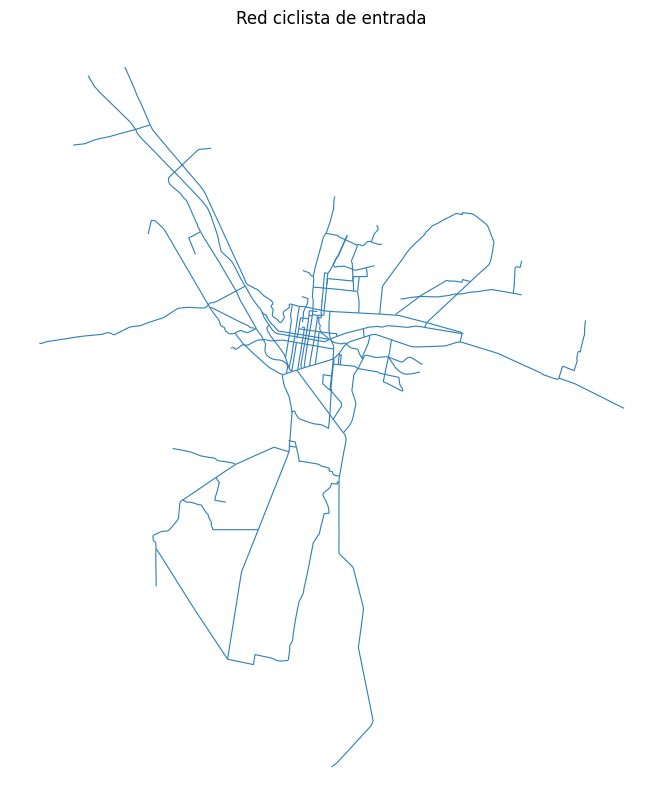

In [70]:
# Limpieza: solo líneas válidas, en CRS métrico y sin multilíneas
if red.crs is None:
    raise ValueError('La capa no tiene CRS definido; asígnalo con red.set_crs(...) antes de continuar.')

red = red[red.geometry.notna() & ~red.geometry.is_empty].copy()
red = red[red.geom_type.isin(['LineString', 'MultiLineString'])]
red = red.to_crs(CRS_METRICO)
red = red.explode(index_parts=False).reset_index(drop=True)
red['geometry'] = shapely.force_2d(red.geometry.values)
red = red[red.length > 0].reset_index(drop=True)

print(f'Segmentos tras limpieza : {len(red):,}')
print(f'Longitud total          : {red.length.sum() / 1000:,.2f} km')

fig, ax = plt.subplots(figsize=(10, 10))
red.plot(ax=ax, color='#2c7fb8', linewidth=0.8)
ax.set_title('Red ciclista de entrada')
ax.set_axis_off()
plt.show()

## 4. Construcción de la topología

1. **Snap:** se redondean las coordenadas a una rejilla de `TOLERANCIA_SNAP` metros para que extremos casi coincidentes compartan vértice.
2. **Nodificación (opcional):** se cortan las líneas en cada cruce para generar vértices en las intersecciones.
3. **Simplificación (opcional):** `line_merge` fusiona segmentos continuos unidos por vértices de grado 2; las intersecciones reales (grado ≥ 3) y los extremos (grado 1) se conservan.

> Los atributos originales se recuperan para cada segmento resultante con una unión espacial al tramo original más cercano.

In [71]:
geoms = red.geometry.values

# 1. Snap a rejilla
if TOLERANCIA_SNAP and TOLERANCIA_SNAP > 0:
    geoms = shapely.set_precision(geoms, grid_size=TOLERANCIA_SNAP)
    geoms = geoms[~shapely.is_empty(geoms)]

# 2. Nodificación (union_all también elimina tramos duplicados/superpuestos)
if NODIFICAR_INTERSECCIONES:
    geoms = shapely.node(shapely.union_all(geoms))
else:
    geoms = shapely.multilinestrings(list(shapely.get_parts(geoms)))

# 3. Fusión de pseudo-nodos
if SIMPLIFICAR_GRADO_2:
    geoms = shapely.line_merge(geoms)

segmentos = gpd.GeoDataFrame(geometry=list(shapely.get_parts(geoms)), crs=CRS_METRICO)
segmentos = segmentos[(segmentos.geom_type == 'LineString') & (segmentos.length > 0)]
segmentos = segmentos.reset_index(drop=True)

# Recuperar atributos del tramo original más cercano (por el punto medio del segmento)
cols_attr = [c for c in red.columns if c != 'geometry']
if cols_attr:
    medios = gpd.GeoDataFrame(
        geometry=segmentos.geometry.interpolate(0.5, normalized=True), crs=CRS_METRICO
    )
    unidos = gpd.sjoin_nearest(medios, red[cols_attr + ['geometry']], how='left')
    unidos = unidos[~unidos.index.duplicated(keep='first')]
    segmentos = segmentos.join(unidos[cols_attr])

segmentos['longitud_m'] = segmentos.length
print(f'Segmentos topológicos : {len(segmentos):,}')

Segmentos topológicos : 274


In [72]:
# Vértices = extremos de cada segmento
coords_ini = shapely.get_coordinates(shapely.get_point(segmentos.geometry.values, 0))
coords_fin = shapely.get_coordinates(shapely.get_point(segmentos.geometry.values, -1))

todas = np.vstack([coords_ini, coords_fin])
claves, inverso = np.unique(np.round(todas, 6), axis=0, return_inverse=True)
inverso = inverso.ravel()

n = len(segmentos)
segmentos['u'] = inverso[:n]
segmentos['v'] = inverso[n:]

nodos = gpd.GeoDataFrame(
    {'node_id': np.arange(len(claves))},
    geometry=gpd.points_from_xy(claves[:, 0], claves[:, 1]),
    crs=CRS_METRICO,
).set_index('node_id')

print(f'Vértices : {len(nodos):,}')

Vértices : 208


## 5. Grafo

Grafo **no dirigido** (la red ciclista se asume transitable en ambos sentidos), ponderado por longitud en metros.
Si hay aristas paralelas entre el mismo par de vértices se conserva la más corta; los bucles (segmentos que inician y terminan en el mismo vértice) se descartan porque no aportan a caminos más cortos.

In [73]:
G = nx.Graph()
for idx, (x, y) in zip(nodos.index, zip(nodos.geometry.x, nodos.geometry.y)):
    G.add_node(idx, x=x, y=y)

for idx, (u, v, l) in enumerate(zip(segmentos['u'], segmentos['v'], segmentos['longitud_m'])):
    if u == v:
        continue
    if G.has_edge(u, v) and G[u][v]['length'] <= l:
        continue
    G.add_edge(u, v, length=l, inv_length=1.0 / l, seg_id=idx)

componentes = sorted(nx.connected_components(G), key=len, reverse=True)
comp_id   = {nd: i for i, c in enumerate(componentes) for nd in c}
comp_size = {nd: len(c) for c in componentes for nd in c}

print(f'Nodos        : {G.number_of_nodes():,}')
print(f'Aristas      : {G.number_of_edges():,}')
print(f'Componentes  : {len(componentes):,}')
print(f'Mayor comp.  : {len(componentes[0]):,} nodos '
      f'({len(componentes[0]) / G.number_of_nodes():.1%} del total)')

if SOLO_COMPONENTE_PRINCIPAL:
    G = G.subgraph(componentes[0]).copy()
    print(f'\nSe trabaja solo con el componente principal: {G.number_of_nodes():,} nodos')

Nodos        : 208
Aristas      : 267
Componentes  : 1
Mayor comp.  : 208 nodos (100.0% del total)


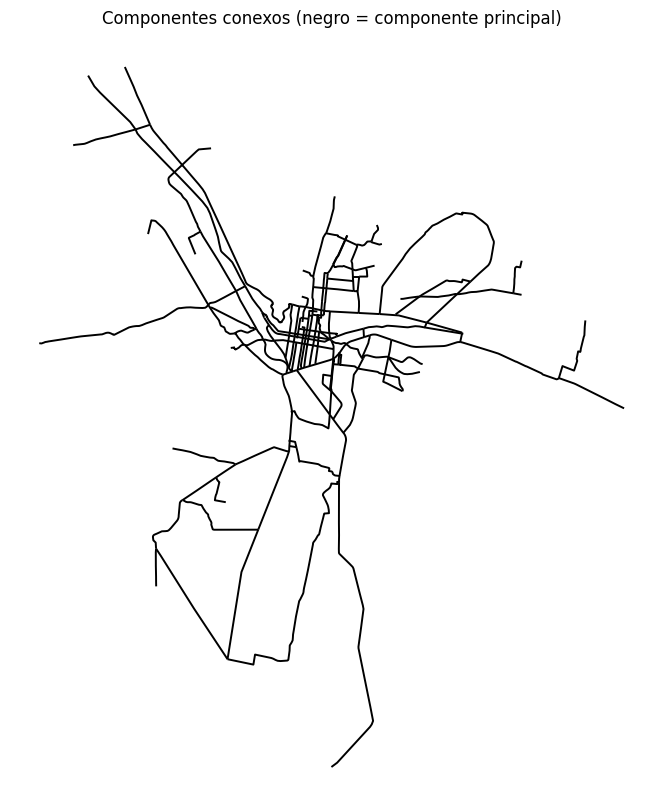

In [74]:
# Diagnóstico: componentes de la red (las redes ciclistas suelen estar fragmentadas)
nodos['componente']     = nodos.index.map(comp_id)
nodos['tam_componente'] = nodos.index.map(comp_size)
segmentos['componente'] = segmentos['u'].map(comp_id)

fig, ax = plt.subplots(figsize=(10, 10))
otros = segmentos[segmentos['componente'] != 0]
if not otros.empty:
    otros.plot(ax=ax, column='componente', cmap='tab20', linewidth=1.0)
segmentos[segmentos['componente'] == 0].plot(ax=ax, color='black', linewidth=1.4)
ax.set_title('Componentes conexos (negro = componente principal)')
ax.set_axis_off()
plt.show()

## 6. Cálculo de centralidades por vértice

> **Betweenness** y **straightness** pueden tardar varios minutos en redes grandes.
> Ajusta `K_BETWEENNESS` y `CALCULAR_STRAIGHTNESS` en los parámetros si es necesario.

In [75]:
%%time
metricas = pd.DataFrame(index=pd.Index(list(G.nodes()), name='node_id'))

# Degree: número de segmentos que llegan al vértice
metricas['degree']            = pd.Series(dict(G.degree()))
metricas['degree_centrality'] = pd.Series(nx.degree_centrality(G))

# Betweenness ponderado por longitud
print('Betweenness...')
metricas['betweenness'] = pd.Series(
    nx.betweenness_centrality(G, k=K_BETWEENNESS, weight='length', normalized=True, seed=42)
)

# Closeness (wf_improved escala por la fracción de nodos alcanzables)
print('Closeness...')
metricas['closeness'] = pd.Series(nx.closeness_centrality(G, distance='length', wf_improved=True))

print('Harmonic closeness...')
harm = pd.Series(nx.harmonic_centrality(G, distance='length'))
metricas['harmonic'] = harm / max(G.number_of_nodes() - 1, 1)

# PageRank ponderado por cercanía (aristas cortas = vínculo más fuerte)
print('PageRank...')
metricas['pagerank'] = pd.Series(nx.pagerank(G, weight='inv_length'))

Betweenness...
Closeness...
Harmonic closeness...
PageRank...
CPU times: total: 297 ms
Wall time: 274 ms


### Straightness centrality

Para cada vértice *i*: promedio sobre los vértices alcanzables *j* de `d_euclidiana(i, j) / d_red(i, j)`.
Valores cercanos a 1 indican que desde ese vértice se llega a los demás por rutas casi en línea recta; valores bajos indican rodeos.

In [76]:
%%time
if CALCULAR_STRAIGHTNESS:
    xy = {nd: np.array([d['x'], d['y']]) for nd, d in G.nodes(data=True)}
    straightness = {}
    for i, (src, dist) in enumerate(nx.all_pairs_dijkstra_path_length(G, weight='length')):
        destinos = [t for t in dist if t != src and dist[t] > 0]
        if not destinos:
            straightness[src] = 0.0
            continue
        d_red = np.fromiter((dist[t] for t in destinos), float)
        d_euc = np.linalg.norm(np.array([xy[t] for t in destinos]) - xy[src], axis=1)
        straightness[src] = float(np.mean(d_euc / d_red))
        if (i + 1) % 1000 == 0:
            print(f'  {i + 1:,} / {G.number_of_nodes():,}')
    metricas['straightness'] = pd.Series(straightness)
else:
    print('Straightness no calculada (CALCULAR_STRAIGHTNESS=False).')

CPU times: total: 93.8 ms
Wall time: 105 ms


### Betweenness local

El betweenness global considera viajes entre **todos** los pares de vértices, incluidos los de punta a punta de la red, que nadie haría en bicicleta. Esto sobrevalora los ejes del centro geométrico de la red.

El **betweenness local** solo cuenta los pares origen–destino separados por **≤ R metros por la red** (`RADIOS_LOCAL`). Para cada vértice de origen se ejecuta un Dijkstra truncado en R y se acumulan los caminos más cortos con el algoritmo de Brandes.

- `betweenness_local_R` (vértice) y `edge_betweenness_local_R` (eje) = **número de pares O–D** a ≤ R m cuyo camino más corto pasa por el vértice / eje (empates repartidos). No se normaliza para que el valor sea interpretable.
- Radios típicos: 2–3 km (viajes cortos, de barrio) y 5 km (viaje ciclista urbano típico).
- Con un radio mayor que el diámetro de la red el resultado coincide con el betweenness global sin normalizar.

In [77]:
from heapq import heappush, heappop
from itertools import count


def betweenness_local(G, radio, weight='length'):
    '''Betweenness de vértices y aristas contando solo pares a <= radio (en unidades de `weight`).

    Brandes (2001) con Dijkstra truncado. Devuelve (dict nodo -> valor, dict seg_id -> valor);
    los valores son número de pares O-D (grafo no dirigido, cada par cuenta una vez).
    '''
    bc_nodos = dict.fromkeys(G, 0.0)
    bc_ejes  = {d['seg_id']: 0.0 for _, _, d in G.edges(data=True)}

    for s in G:
        # Dijkstra truncado en `radio`, registrando predecesores y número de caminos
        S, P, sigma, D = [], {s: []}, {s: 1.0}, {}
        visto = {s: 0.0}
        c = count()
        heap = [(0.0, next(c), s, s)]
        while heap:
            dist, _, pred, v = heappop(heap)
            if v in D:
                continue
            sigma[v] += sigma[pred] if v != s else 0.0
            S.append(v)
            D[v] = dist
            for w, datos in G[v].items():
                vw = dist + datos[weight]
                if vw > radio:
                    continue
                if w not in D and (w not in visto or vw < visto[w]):
                    visto[w] = vw
                    heappush(heap, (vw, next(c), v, w))
                    sigma[w] = 0.0
                    P[w] = [v]
                elif vw == visto[w]:
                    sigma[w] += sigma[v]
                    P[w].append(v)

        # Acumulación de dependencias (de los más lejanos a los más cercanos)
        delta = dict.fromkeys(S, 0.0)
        while S:
            w = S.pop()
            coef = (1.0 + delta[w]) / sigma[w]
            for v in P[w]:
                aporte = sigma[v] * coef
                bc_ejes[G[v][w]['seg_id']] += aporte
                delta[v] += aporte
            if w != s:
                bc_nodos[w] += delta[w]

    # Grafo no dirigido: cada par se recorrió desde ambos extremos
    bc_nodos = {k: v / 2 for k, v in bc_nodos.items()}
    bc_ejes  = {k: v / 2 for k, v in bc_ejes.items()}
    return bc_nodos, bc_ejes

In [78]:
%%time
eb_local = {}   # radio -> {seg_id: valor}; se usa en la sección 9 (ejes)
for R in RADIOS_LOCAL:
    print(f'Betweenness local R = {R:,} m...')
    bc_n, bc_e = betweenness_local(G, R)
    metricas[f'betweenness_local_{R}'] = pd.Series(bc_n)
    eb_local[R] = bc_e

Betweenness local R = 2,000 m...
Betweenness local R = 5,000 m...
CPU times: total: 109 ms
Wall time: 108 ms


In [79]:
nodos_cent = nodos.join(metricas, how='inner')
cols_metricas = [c for c in ['degree', 'degree_centrality', 'betweenness', 'closeness',
                             'harmonic', 'straightness', 'pagerank']
                 + [f'betweenness_local_{R}' for R in RADIOS_LOCAL] if c in nodos_cent.columns]

print(f'Vértices con métricas: {len(nodos_cent):,}')
nodos_cent[cols_metricas].describe().T

Vértices con métricas: 208


,count,mean,std,min,25%,50%,75%,max
degree,208.0,2.567308,1.237610,1.000000,1.000000,3.000000,4.000000,5.000000
degree_centrality,208.0,0.012402,0.005979,0.004831,0.004831,0.014493,0.019324,0.024155
betweenness,208.0,0.050018,0.064010,0.000000,0.000000,0.022021,0.081539,0.261573
closeness,208.0,0.000177,0.000058,0.000046,0.000132,0.000184,0.000230,0.000257
harmonic,208.0,0.000694,0.001995,0.000048,0.000191,0.000318,0.000560,0.019314
straightness,208.0,0.737853,0.073361,0.406305,0.697970,0.754600,0.788147,0.879825
pagerank,208.0,0.004808,0.003063,0.000731,0.002259,0.004510,0.006358,0.016803
betweenness_local_2000,208.0,60.865385,116.814404,0.000000,0.000000,2.000000,55.750000,530.000000
betweenness_local_5000,208.0,331.716346,520.489384,0.000000,0.000000,40.000000,449.500000,2164.000000


## 7. Mapas por métrica

Cada mapa muestra la red en gris y los vértices coloreados por la métrica (escala recortada al percentil 99 para que los valores extremos no aplasten la escala). El tamaño del punto también crece con el valor.

In [80]:
def plot_node_metric(col, titulo, cmap='YlOrRd'):
    datos = nodos_cent.sort_values(col)  # valores altos se dibujan encima
    vals  = datos[col]
    norm  = mcolors.Normalize(vmin=vals.min(), vmax=np.quantile(vals, 0.99))

    fig, ax = plt.subplots(figsize=(11, 11))
    segmentos.plot(ax=ax, color='#bbbbbb', linewidth=0.6, zorder=1)
    ax.scatter(datos.geometry.x, datos.geometry.y,
               c=vals, cmap=cmap, norm=norm,
               s=4 + 40 * np.clip(norm(vals), 0, 1), zorder=2, linewidths=0)
    sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
    fig.colorbar(sm, ax=ax, shrink=0.45, label=col)
    ax.set_title(titulo, fontsize=13)
    ax.set_axis_off()
    plt.tight_layout()
    plt.show()

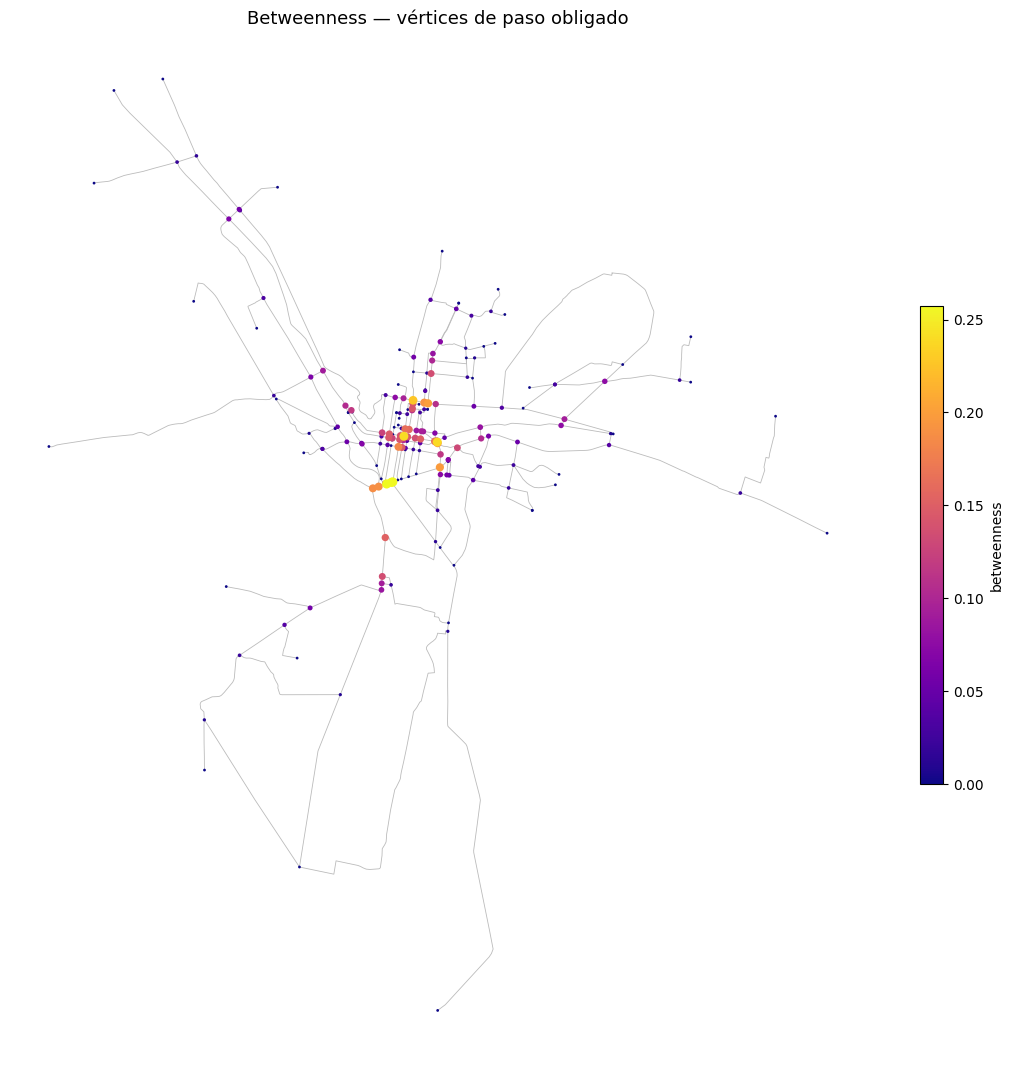

In [81]:
plot_node_metric('betweenness', 'Betweenness — vértices de paso obligado', 'plasma')

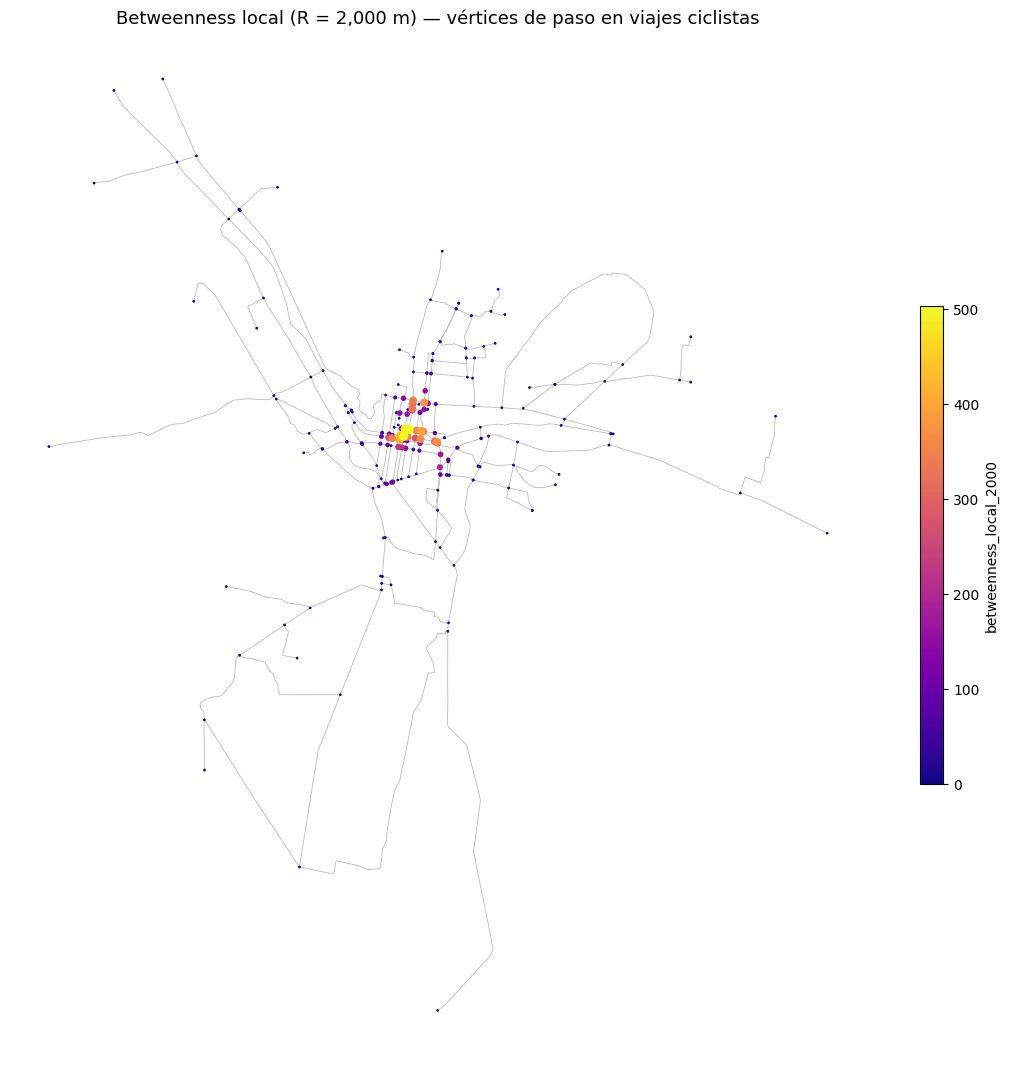

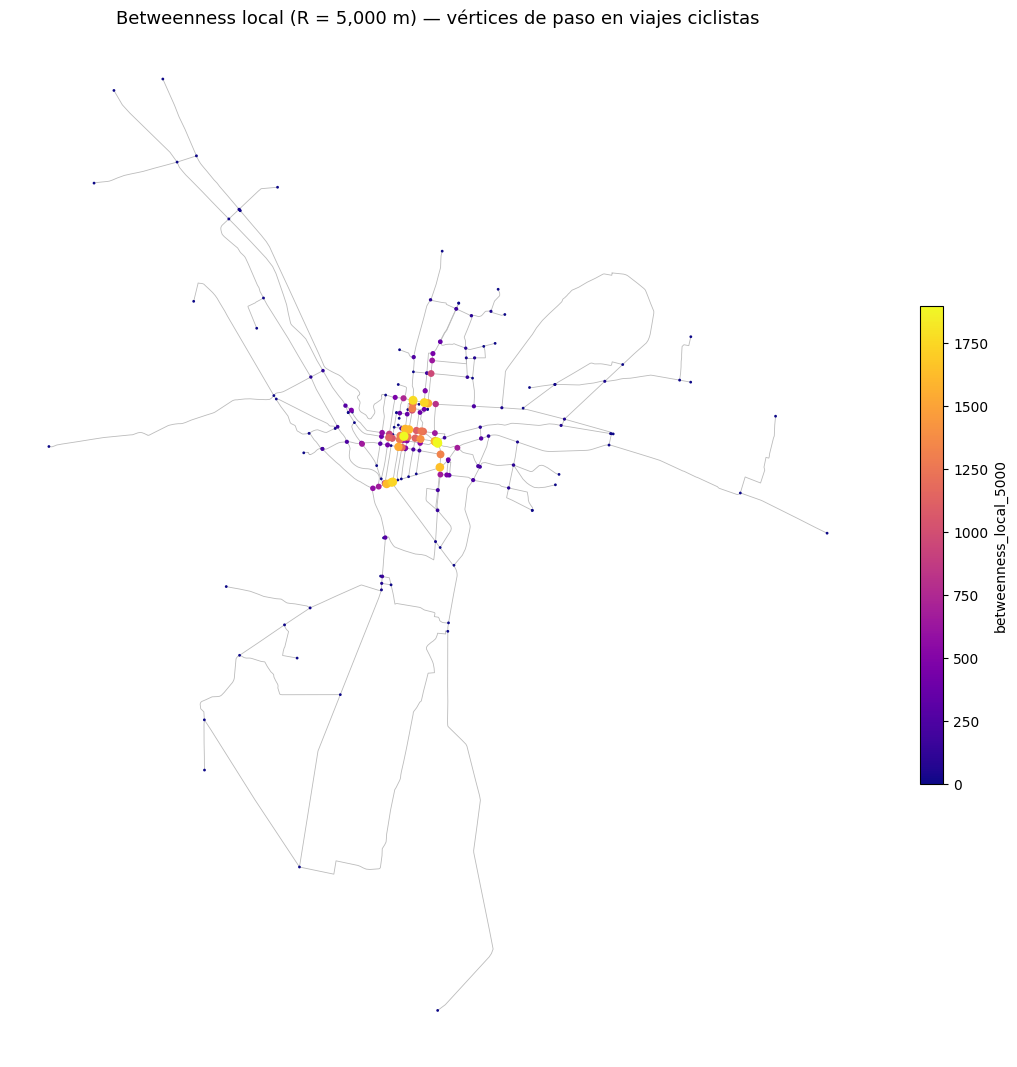

In [82]:
for R in RADIOS_LOCAL:
    plot_node_metric(f'betweenness_local_{R}',
                     f'Betweenness local (R = {R:,} m) — vértices de paso en viajes ciclistas', 'plasma')

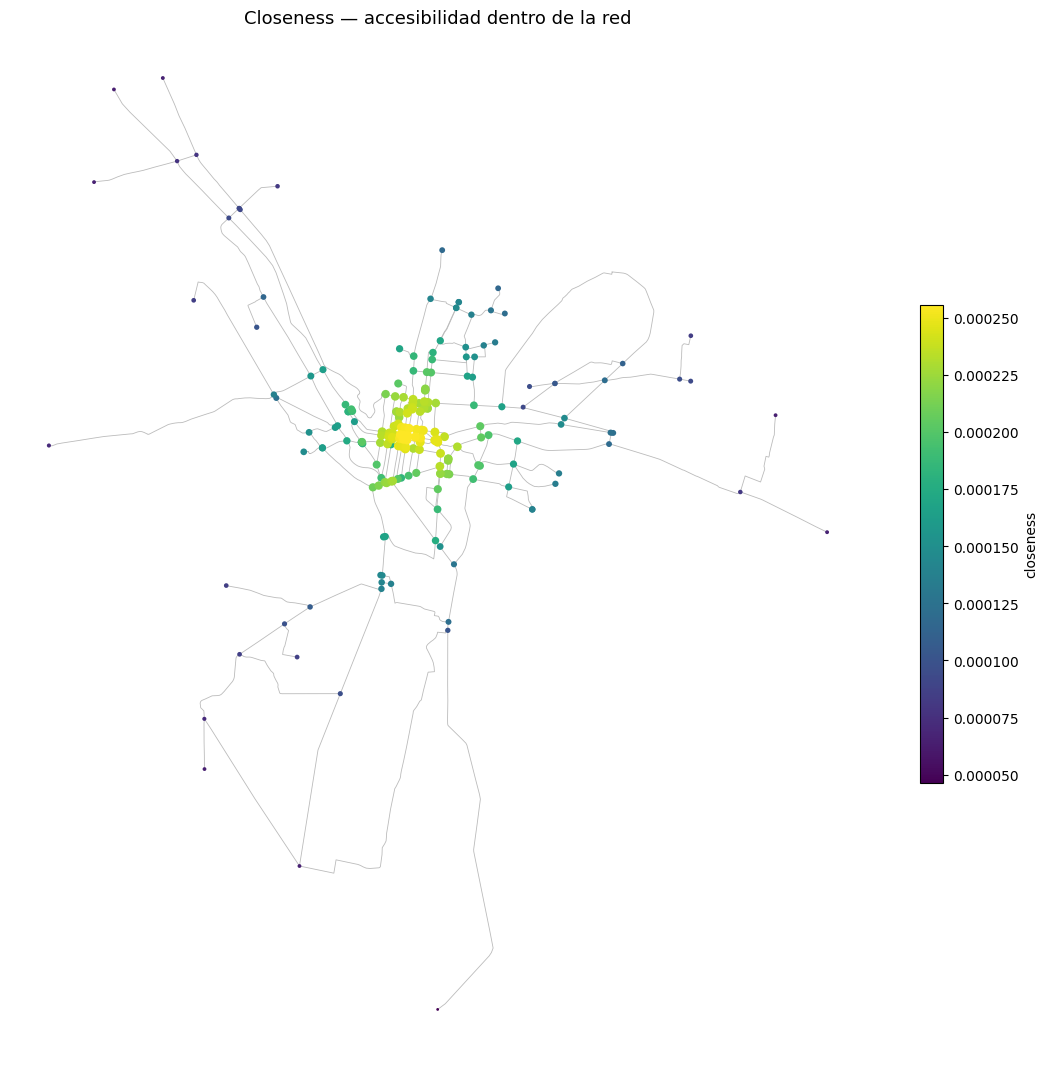

In [83]:
plot_node_metric('closeness', 'Closeness — accesibilidad dentro de la red', 'viridis')

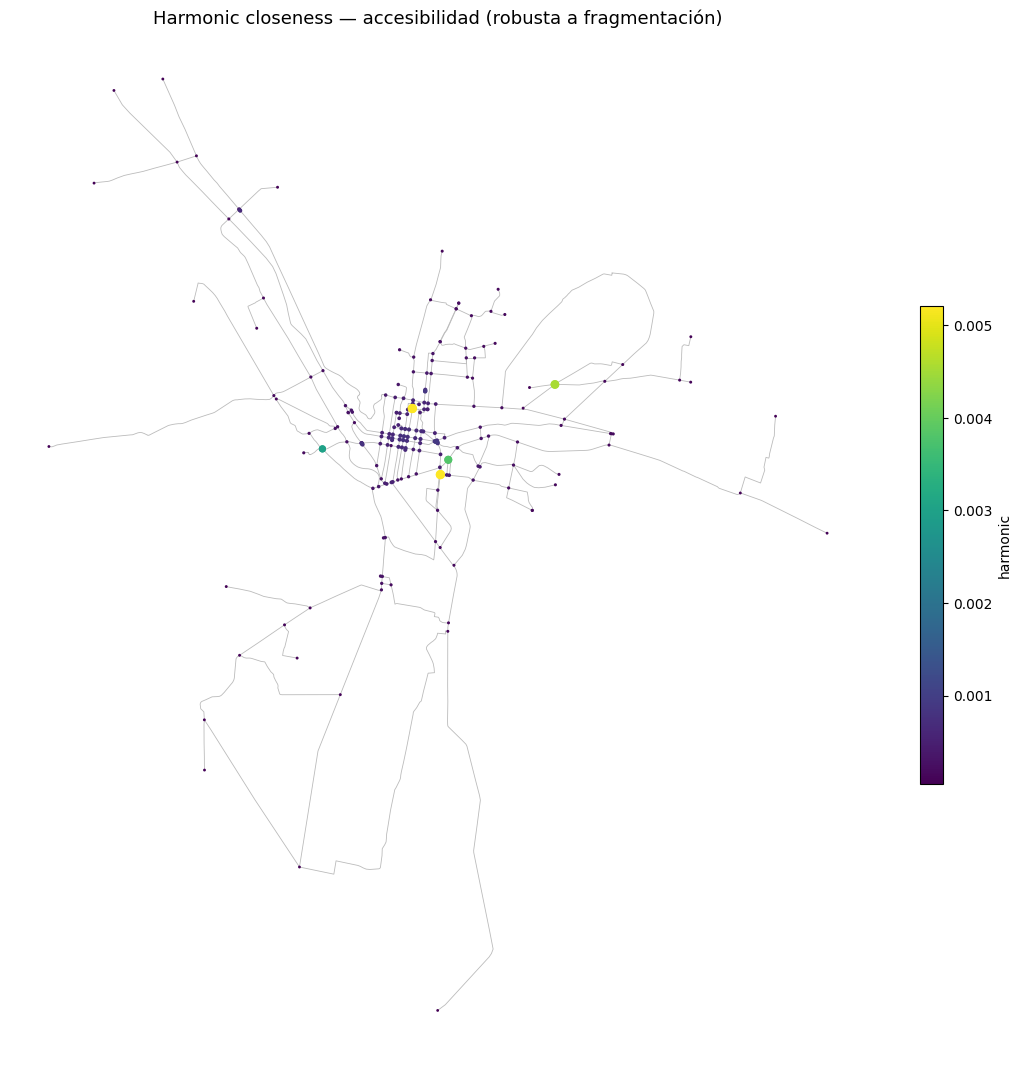

In [84]:
plot_node_metric('harmonic', 'Harmonic closeness — accesibilidad (robusta a fragmentación)', 'viridis')

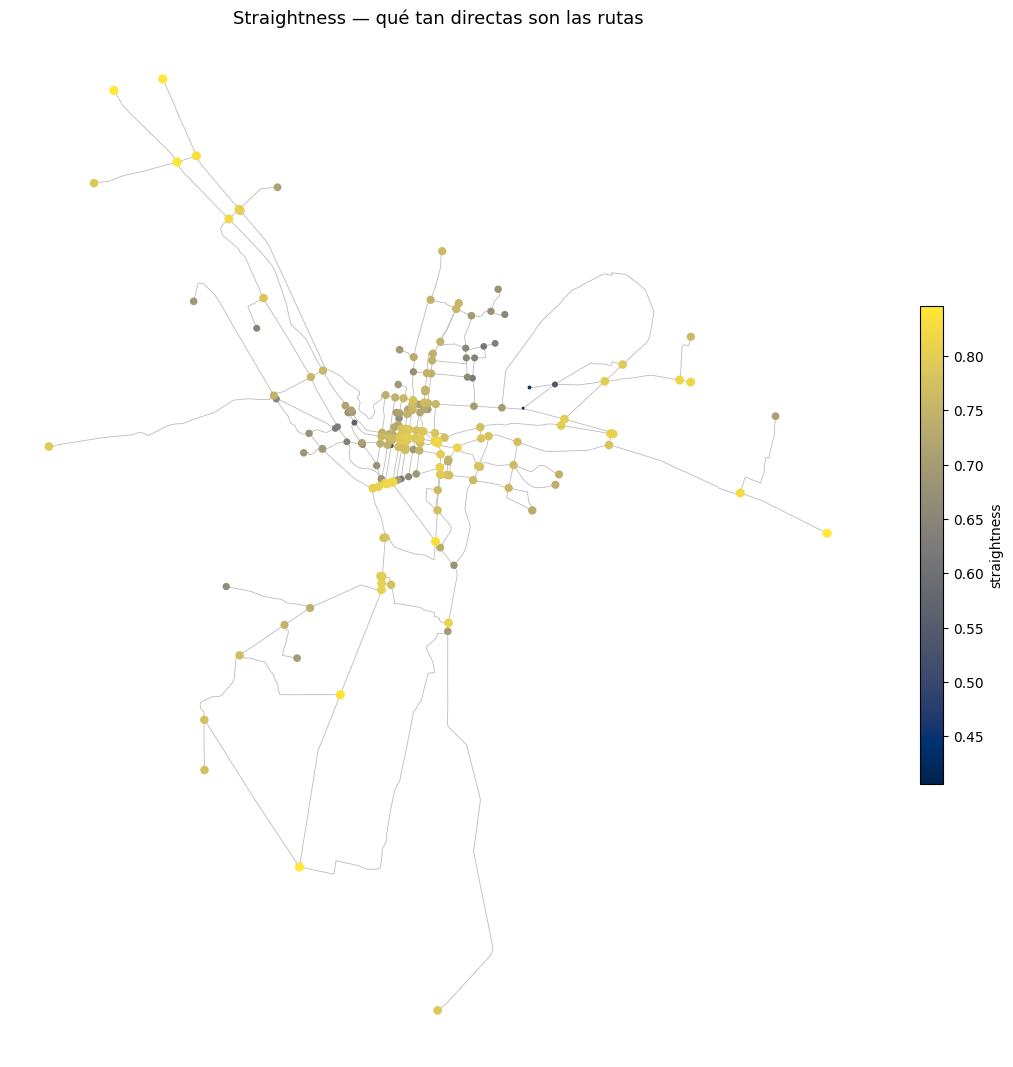

In [85]:
if 'straightness' in nodos_cent.columns:
    plot_node_metric('straightness', 'Straightness — qué tan directas son las rutas', 'cividis')

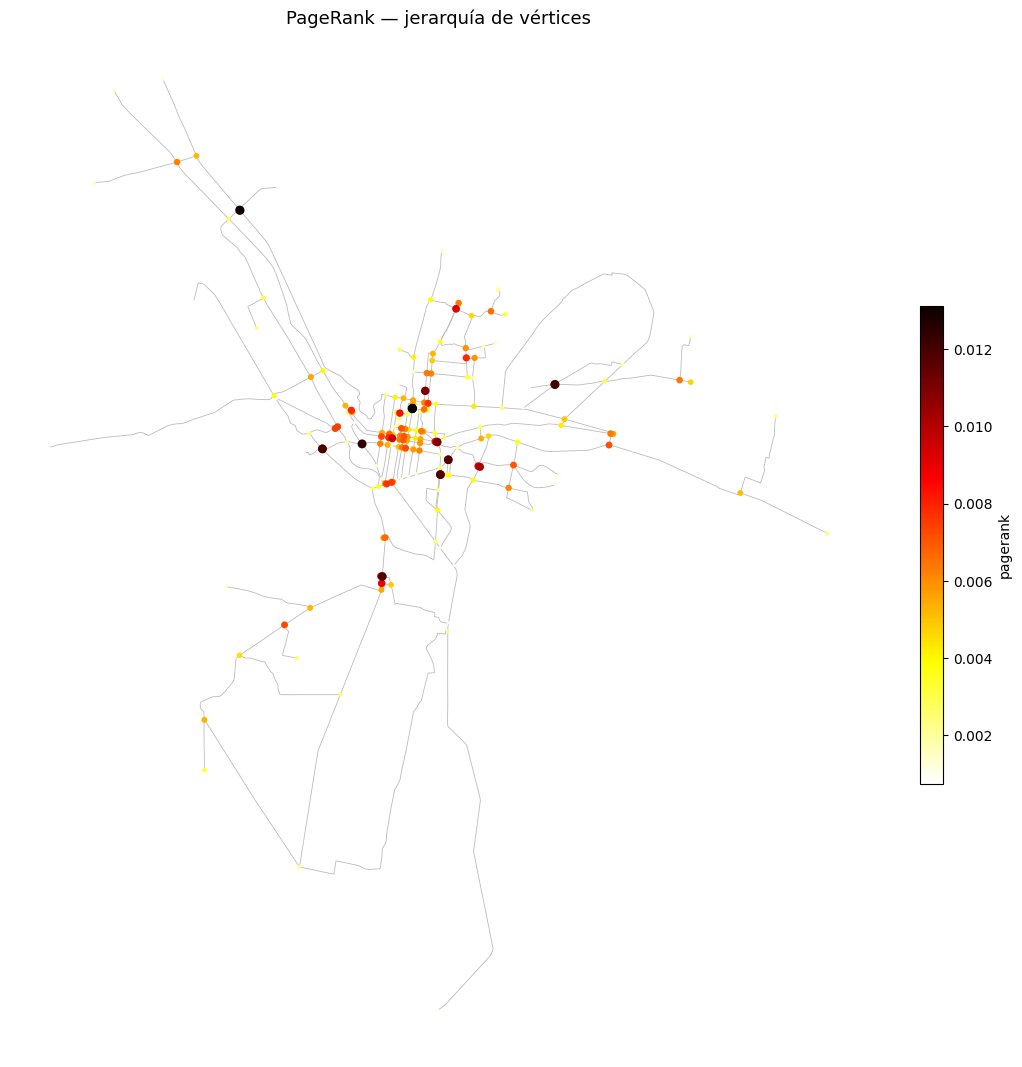

In [86]:
plot_node_metric('pagerank', 'PageRank — jerarquía de vértices', 'hot_r')

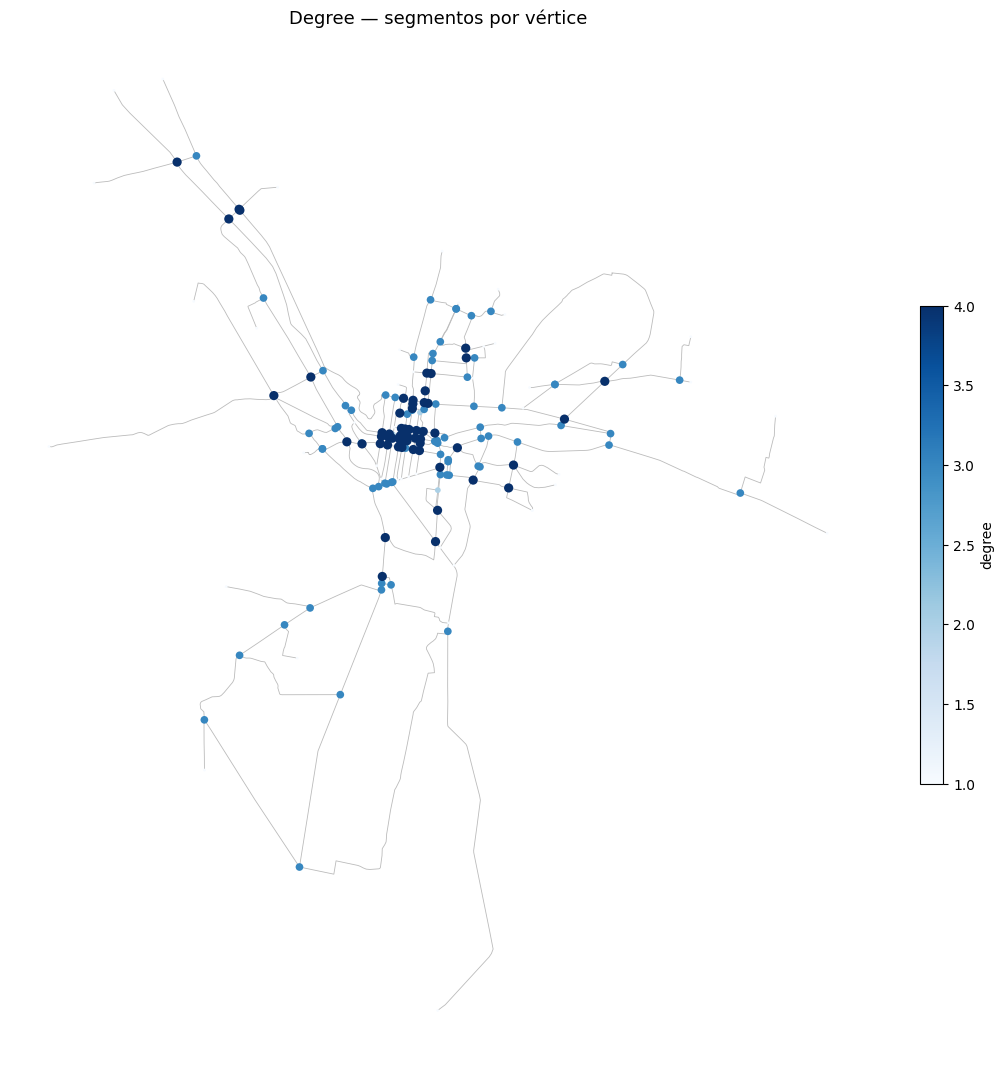

In [87]:
plot_node_metric('degree', 'Degree — segmentos por vértice', 'Blues')

## 8. Correlación entre métricas y ranking

Una correlación alta entre dos métricas indica que capturan la misma estructura; correlaciones bajas indican que aportan información complementaria.

In [88]:
corr = nodos_cent[cols_metricas].corr(method='spearman')
corr.style.background_gradient(cmap='RdBu_r', vmin=-1, vmax=1).format('{:.2f}')

,degree,degree_centrality,betweenness,closeness,harmonic,straightness,pagerank,betweenness_local_2000,betweenness_local_5000
degree,1.00,1.00,0.79,0.40,0.38,0.36,0.56,0.74,0.79
degree_centrality,1.00,1.00,0.79,0.40,0.38,0.36,0.56,0.74,0.79
betweenness,0.79,0.79,1.00,0.52,0.50,0.45,0.54,0.83,0.93
closeness,0.40,0.40,0.52,1.00,0.84,0.10,0.28,0.71,0.65
harmonic,0.38,0.38,0.50,0.84,1.00,0.07,0.54,0.70,0.61
straightness,0.36,0.36,0.45,0.10,0.07,1.00,0.27,0.29,0.37
pagerank,0.56,0.56,0.54,0.28,0.54,0.27,1.00,0.56,0.56
betweenness_local_2000,0.74,0.74,0.83,0.71,0.70,0.29,0.56,1.00,0.95
betweenness_local_5000,0.79,0.79,0.93,0.65,0.61,0.37,0.56,0.95,1.00


In [89]:
TOP_N = 20
ranking = nodos_cent[cols_metricas].sort_values('betweenness', ascending=False).head(TOP_N)
ranking.style.background_gradient(cmap='YlOrRd')

,degree,degree_centrality,betweenness,closeness,harmonic,straightness,pagerank,betweenness_local_2000,betweenness_local_5000
node_id,,,,,,,,,
70,3,0.014493,0.261573,0.000228,0.000530,0.820485,0.006104,120.000000,1740.000000
67,3,0.014493,0.260354,0.000227,0.000539,0.819645,0.007527,94.000000,1674.000000
61,3,0.014493,0.258806,0.000223,0.000499,0.818067,0.007663,85.000000,1619.000000
90,4,0.019324,0.239857,0.000257,0.000768,0.794704,0.007068,530.000000,1937.000000
137,3,0.014493,0.238638,0.000248,0.000898,0.817781,0.011029,364.000000,2164.000000
104,4,0.019324,0.226819,0.000236,0.000596,0.778123,0.005542,341.000000,1773.000000
126,4,0.019324,0.200084,0.000232,0.000554,0.759991,0.007695,166.000000,1544.000000
142,5,0.024155,0.197739,0.000233,0.000476,0.806850,0.002530,198.000000,1647.000000
140,3,0.014493,0.194456,0.000247,0.000789,0.814223,0.005891,235.000000,1909.000000


## 9. Centralidad sobre los ejes

Se asignan métricas a cada segmento (eje) de la red de dos formas:

- **Edge betweenness (nativa):** fracción de caminos más cortos que recorren el eje. Se calcula directamente sobre las aristas del grafo, por lo que es la medida más fiel de "flujo potencial" por tramo.
- **Edge betweenness local (nativa):** igual, pero solo con pares O–D a ≤ R metros (`edge_betweenness_local_R`); ver sección 6.
- **Métricas nodales transferidas:** cada eje recibe el **promedio** de los valores de sus dos vértices extremos (`<métrica>_prom`) y, para betweenness, también el **máximo** (`betweenness_max`), útil para resaltar ejes que llegan a un vértice crítico.

> Los ejes que no forman parte del grafo (bucles, aristas paralelas descartadas o, si `SOLO_COMPONENTE_PRINCIPAL=True`, ejes de otros componentes) quedan con `edge_betweenness` vacía.

In [90]:
%%time
# 1. Edge betweenness nativa, ponderada por longitud
print('Edge betweenness...')
eb = nx.edge_betweenness_centrality(G, k=K_BETWEENNESS, weight='length', normalized=True, seed=42)
eb_por_seg = {G[u][v]['seg_id']: val for (u, v), val in eb.items()}
segmentos['edge_betweenness'] = segmentos.index.map(eb_por_seg)

# Edge betweenness local (calculada en la sección 6)
for R in RADIOS_LOCAL:
    segmentos[f'edge_betweenness_local_{R}'] = segmentos.index.map(eb_local[R])

# 2. Métricas nodales transferidas a los ejes (promedio de los extremos)
cols_nodales_ejes = [c for c in cols_metricas
                     if c != 'degree_centrality' and not c.startswith('betweenness_local')]
for col in cols_nodales_ejes:
    val_u = segmentos['u'].map(nodos_cent[col])
    val_v = segmentos['v'].map(nodos_cent[col])
    segmentos[f'{col}_prom'] = (val_u + val_v) / 2
    if col == 'betweenness':
        segmentos['betweenness_max'] = np.fmax(val_u, val_v)

cols_ejes = (['edge_betweenness'] + [f'edge_betweenness_local_{R}' for R in RADIOS_LOCAL]) + [f'{c}_prom' for c in cols_nodales_ejes] + ['betweenness_max']
print(f'Ejes con edge betweenness: {segmentos["edge_betweenness"].notna().sum():,} de {len(segmentos):,}')
segmentos[cols_ejes].describe().T

Edge betweenness...
Ejes con edge betweenness: 267 de 274
CPU times: total: 281 ms
Wall time: 272 ms


,count,mean,std,min,25%,50%,75%,max
edge_betweenness,267.0,0.042336,0.049220,0.000000,0.009615,0.019277,0.058296,0.261659
edge_betweenness_local_2000,267.0,59.408240,91.995188,0.000000,2.500000,18.000000,70.000000,426.000000
edge_betweenness_local_5000,267.0,295.430712,401.265711,0.000000,27.000000,126.000000,392.000000,2002.000000
degree_prom,274.0,3.147810,0.658180,2.000000,2.500000,3.000000,3.500000,4.500000
betweenness_prom,274.0,0.067466,0.057136,0.000000,0.020238,0.050631,0.094525,0.260963
closeness_prom,274.0,0.000187,0.000055,0.000068,0.000145,0.000201,0.000235,0.000257
harmonic_prom,274.0,0.000784,0.001678,0.000075,0.000239,0.000436,0.000648,0.019314
straightness_prom,274.0,0.749822,0.057950,0.475622,0.724873,0.758673,0.789758,0.858176
pagerank_prom,274.0,0.005602,0.002211,0.001596,0.004001,0.005361,0.006677,0.013989
betweenness_max,274.0,0.091193,0.068512,0.000000,0.029267,0.073261,0.143204,0.261573


In [91]:
def plot_edge_metric(col, titulo, cmap='plasma', bgcolor='#111111'):
    datos = segmentos.dropna(subset=[col]).sort_values(col)  # valores altos se dibujan encima
    vals  = datos[col]
    norm  = mcolors.Normalize(vmin=vals.min(), vmax=np.quantile(vals, 0.99))

    fig, ax = plt.subplots(figsize=(11, 11), facecolor=bgcolor)
    ax.set_facecolor(bgcolor)
    segmentos[segmentos[col].isna()].plot(ax=ax, color='#444444', linewidth=0.5)
    datos.plot(ax=ax, color=plt.get_cmap(cmap)(norm(vals)),
               linewidth=0.5 + 3.0 * np.clip(norm(vals), 0, 1))
    sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
    cb = fig.colorbar(sm, ax=ax, shrink=0.45)
    cb.set_label(col, color='white')
    cb.ax.yaxis.set_tick_params(color='white', labelcolor='white')
    ax.set_title(titulo, color='white', fontsize=13)
    ax.set_axis_off()
    plt.tight_layout()
    plt.show()

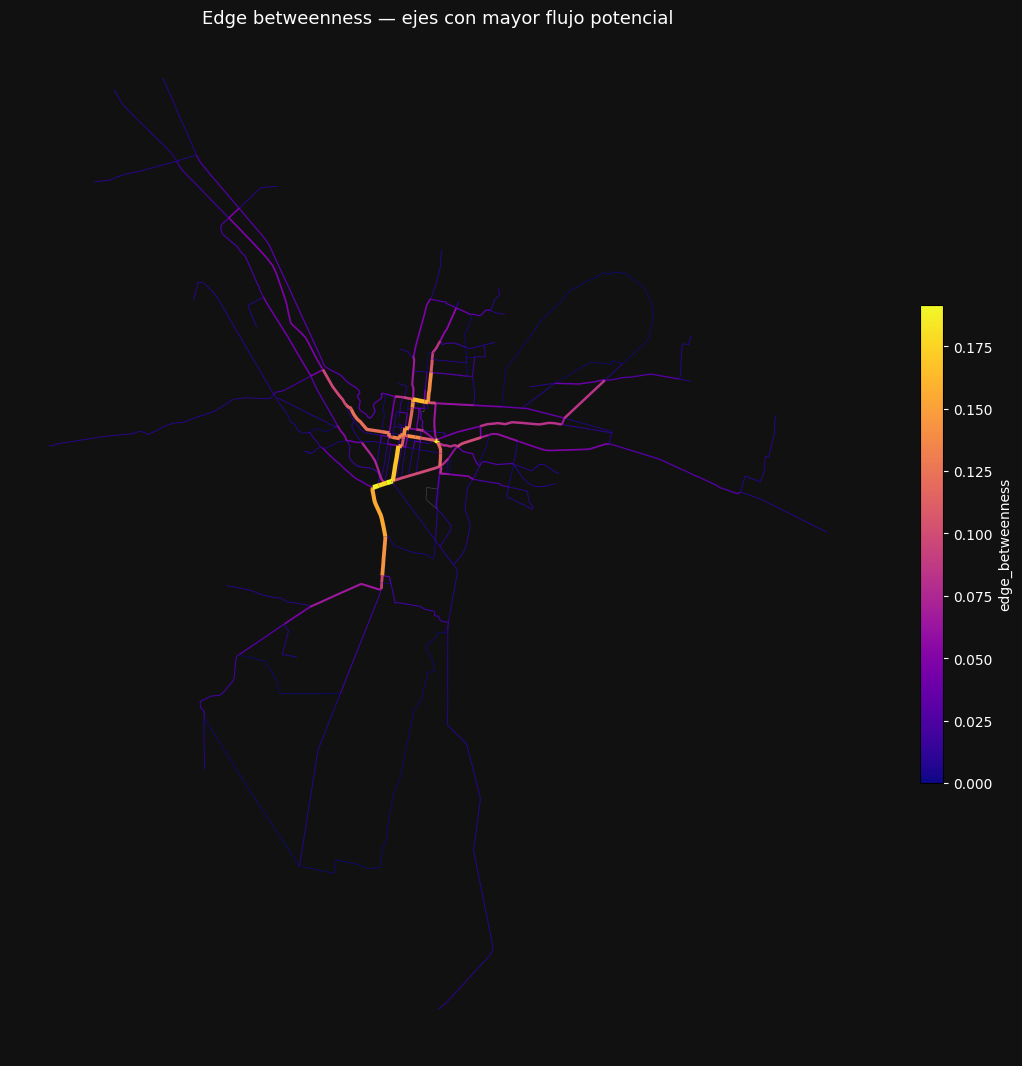

In [92]:
plot_edge_metric('edge_betweenness', 'Edge betweenness — ejes con mayor flujo potencial', 'plasma')

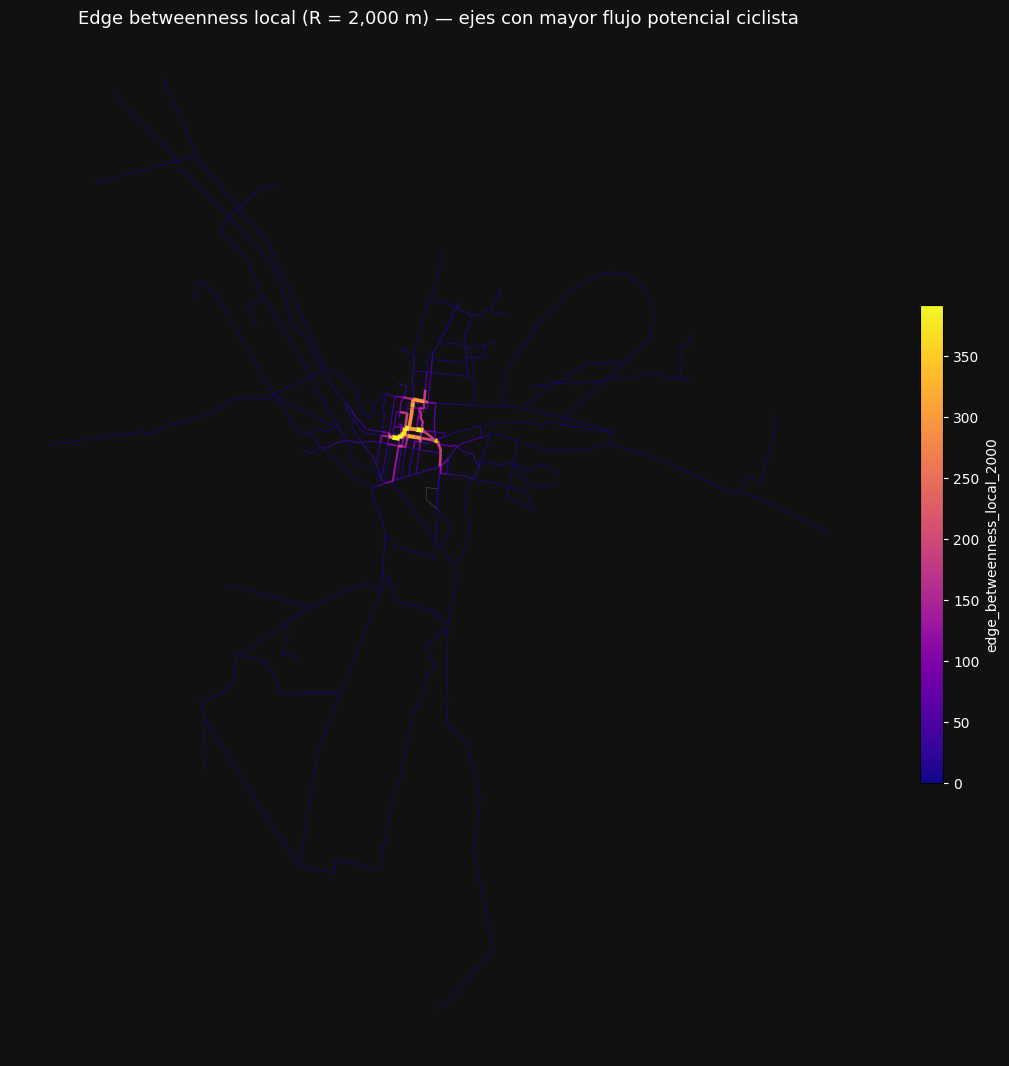

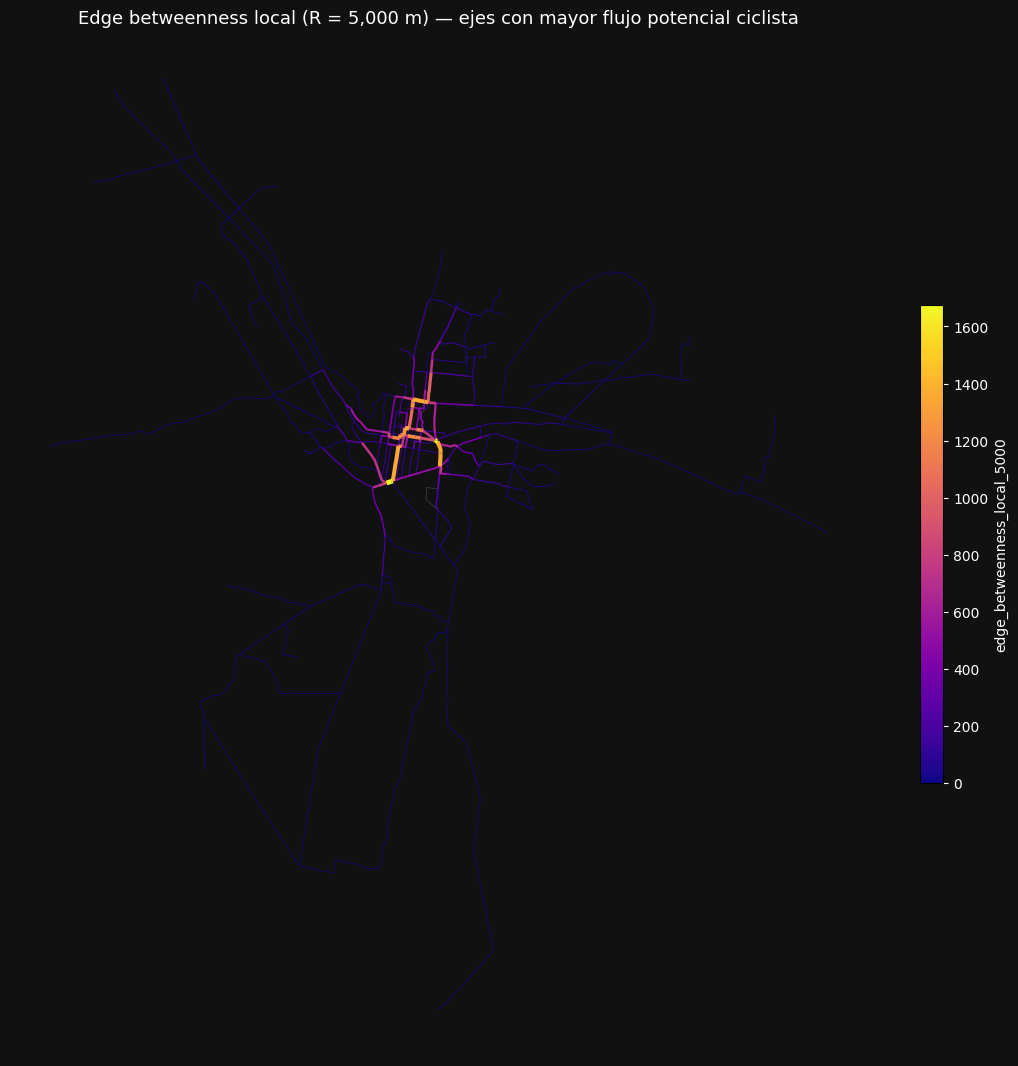

In [93]:
for R in RADIOS_LOCAL:
    plot_edge_metric(f'edge_betweenness_local_{R}',
                     f'Edge betweenness local (R = {R:,} m) — ejes con mayor flujo potencial ciclista', 'plasma')

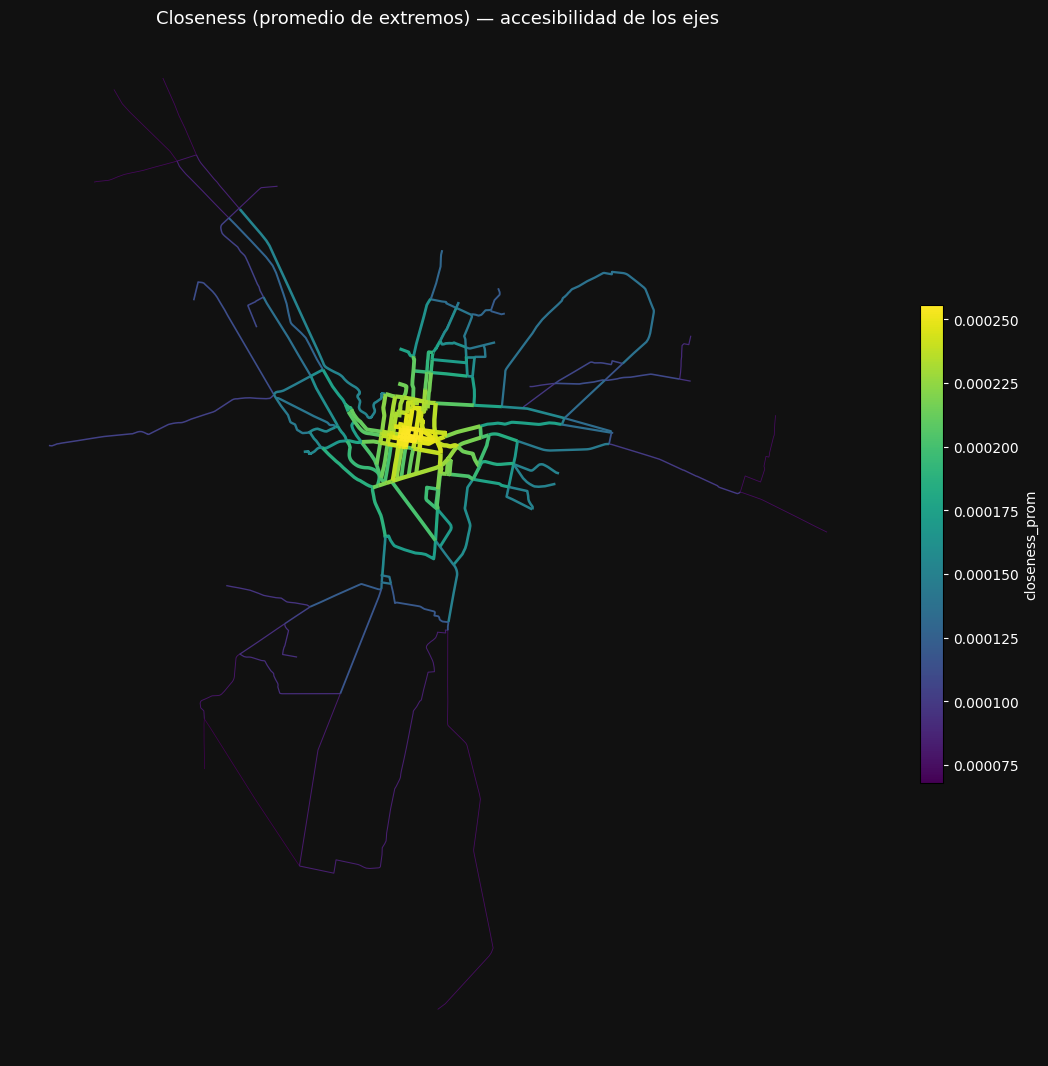

In [94]:
plot_edge_metric('closeness_prom', 'Closeness (promedio de extremos) — accesibilidad de los ejes', 'viridis')

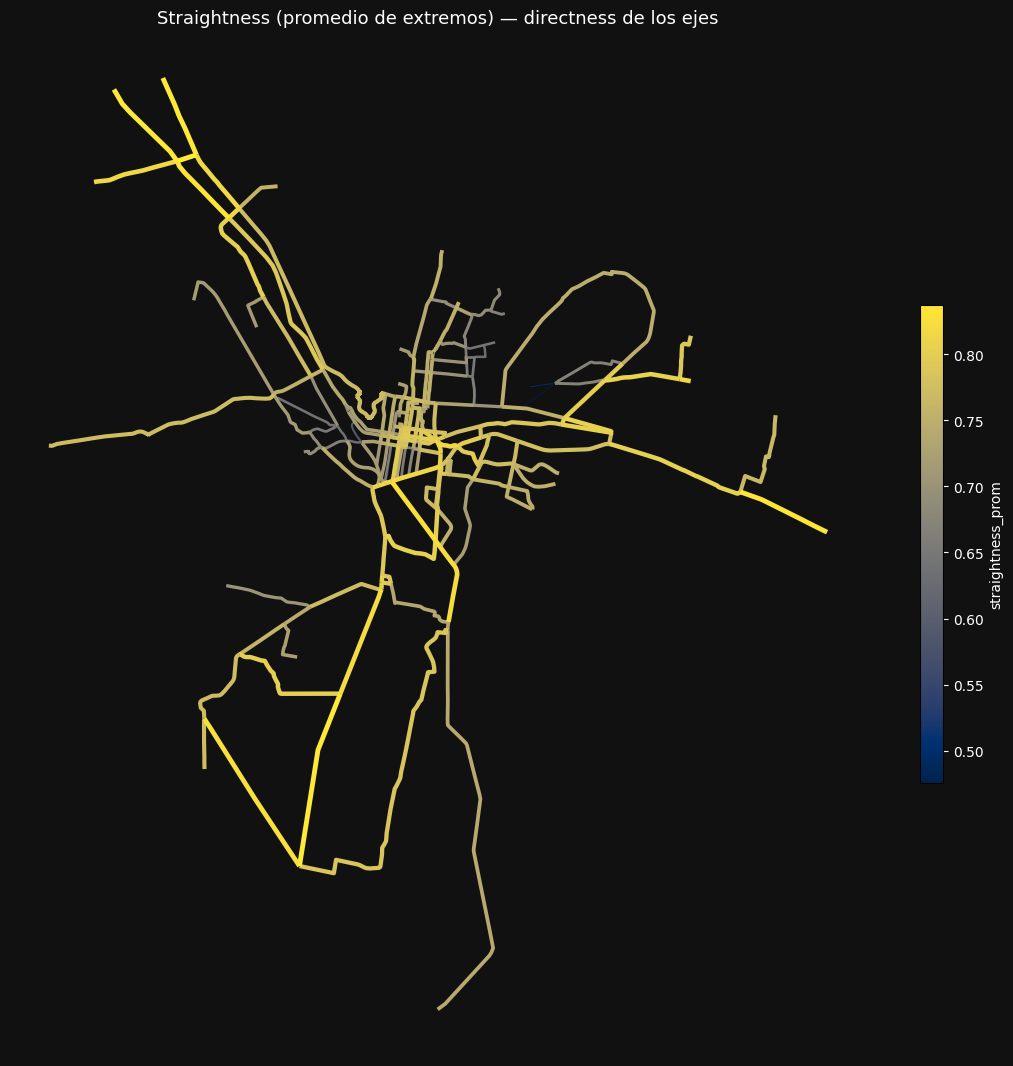

In [95]:
if 'straightness_prom' in segmentos.columns:
    plot_edge_metric('straightness_prom', 'Straightness (promedio de extremos) — directness de los ejes', 'cividis')

In [96]:
# Ejes más relevantes por edge betweenness (incluye los atributos originales de la capa)
TOP_N_EJES = 20
cols_tabla = cols_attr + ['longitud_m'] + cols_ejes
(segmentos.sort_values('edge_betweenness', ascending=False)
          .head(TOP_N_EJES)[cols_tabla]
          .style.background_gradient(subset=cols_ejes, cmap='YlOrRd'))

KeyError: '`Styler.apply` and `.map` are not compatible with non-unique index or columns.'

## 10. Mapa interactivo

Requiere `folium`. Cambia `METRICA_MAPA` para visualizar otra columna.

In [97]:
import folium
import branca.colormap as bcm

METRICA_MAPA = 'betweenness'

seg_wgs   = segmentos[['longitud_m', 'componente', 'geometry']].to_crs('EPSG:4326')
nodos_wgs = nodos_cent.reset_index()[['node_id'] + cols_metricas + ['geometry']].to_crs('EPSG:4326')

vals = nodos_wgs[METRICA_MAPA]
cmap_folium = bcm.LinearColormap(['#0d0887', '#cc4778', '#f0f921'],
                                 vmin=vals.min(), vmax=np.quantile(vals, 0.99),
                                 caption=METRICA_MAPA)

minx, miny, maxx, maxy = seg_wgs.total_bounds
m = folium.Map(tiles='CartoDB positron')
m.fit_bounds([[miny, minx], [maxy, maxx]])

folium.GeoJson(seg_wgs, name='Red ciclista',
               style_function=lambda f: {'color': 'gray', 'weight': 2}).add_to(m)

capa_nodos = folium.FeatureGroup(name='Vértices').add_to(m)
for _, r in nodos_wgs.sort_values(METRICA_MAPA).iterrows():
    popup = '<br>'.join(f'<b>{c}</b>: {r[c]:.5g}' for c in ['node_id'] + cols_metricas)
    folium.CircleMarker([r.geometry.y, r.geometry.x], radius=4, weight=0,
                        fill=True, fill_opacity=0.9,
                        fill_color=cmap_folium(min(r[METRICA_MAPA], cmap_folium.vmax)),
                        popup=folium.Popup(popup, max_width=250)).add_to(capa_nodos)

cmap_folium.add_to(m)
folium.LayerControl().add_to(m)
m

## 11. Exportar resultados

In [98]:
os.makedirs(OUTPUT_DIR, exist_ok=True)
ruta_salida = f'{OUTPUT_DIR}/{NOMBRE_SALIDA}.gpkg'

salida_nodos = nodos_cent.reset_index()[['node_id', 'componente', 'tam_componente']
                                        + cols_metricas + ['geometry']]
salida_nodos.to_file(ruta_salida, layer='nodos_centralidad', driver='GPKG')
segmentos.to_file(ruta_salida, layer='segmentos', driver='GPKG')
salida_nodos.drop(columns='geometry').to_csv(f'{OUTPUT_DIR}/{NOMBRE_SALIDA}_nodos.csv', index=False)

print(f'Exportado en: {ruta_salida}')
print(f'  capa nodos_centralidad — {", ".join(cols_metricas)}')
print(f'  capa segmentos         — u, v, longitud_m, {", ".join(c for c in cols_ejes if c in segmentos.columns)}')
print(f'Tabla: {OUTPUT_DIR}/{NOMBRE_SALIDA}_nodos.csv')

Exportado en: datos/red_ciclista/red_ciclista_centralidad.gpkg
  capa nodos_centralidad — degree, degree_centrality, betweenness, closeness, harmonic, straightness, pagerank, betweenness_local_2000, betweenness_local_5000
  capa segmentos         — u, v, longitud_m, edge_betweenness, edge_betweenness_local_2000, edge_betweenness_local_5000, degree_prom, betweenness_prom, closeness_prom, harmonic_prom, straightness_prom, pagerank_prom, betweenness_max
Tabla: datos/red_ciclista/red_ciclista_centralidad_nodos.csv
